# Aula 02 — Assistente Virtual em Tempo Real: por que a atenção custa caro?

**Disciplina: Engenharia de Machine Learning — FIAP PosTech**

---

## 🎯 Objetivo da aula

Nesta aula, vamos entender, na prática, **um** conceito central de performance em NLP:

> **A complexidade quadrática O(n²) do mecanismo de atenção dos Transformers** e por que ela é o principal gargalo de latência quando um assistente virtual precisa responder em tempo real.

Vamos:

1. Entender o problema do assistente virtual de voz.
2. Explicar de forma simples o que é a atenção e por que ela é O(n²).
3. Implementar uma atenção mínima em NumPy.
4. Medir na prática como a latência cresce com o tamanho da pergunta.
5. Interpretar os resultados e discutir alternativas eficientes.
6. Concluir com os principais aprendizados.

## ✅ Pré-requisitos

Antes de executar este notebook, garanta o seguinte:

### 1. Software necessário

| Item | Versão mínima | Observação |
|---|---|---|
| **Python** | 3.10+ | Verifique com `python --version` |
| **Jupyter** | 1.0+ | Para abrir e executar o notebook |
| **NumPy** | 1.24+ | Álgebra linear / atenção |
| **Matplotlib** | 3.7+ | Visualizações |

Este notebook é **leve e autocontido**: usa apenas `numpy` e `matplotlib`. Não requer GPU, internet ou datasets externos.

### 2. Instalação das dependências

Escolha **uma** das opções abaixo.

**Opção A — no terminal (recomendado):**

```bash
# a partir da pasta 02_desafios_performance_nlp_audio
pip install -r requirements.txt

# ou, o mínimo para este notebook:
pip install numpy matplotlib jupyter
```

**Opção B — direto no notebook:** execute a célula de instalação logo abaixo (descomente a linha `%pip install ...`).

### 3. Selecionar o kernel correto

No canto superior direito do notebook, clique em **"Select Kernel"** e escolha o interpretador Python onde as dependências foram instaladas. Se aparecer `ModuleNotFoundError: No module named 'numpy'`, quase sempre significa que o kernel selecionado não é o mesmo ambiente da instalação — selecione o kernel certo (ou rode a célula de instalação abaixo) e execute novamente.


## 1. Contexto do problema e motivação

Imagine um **assistente virtual de compras por voz**. O usuário pergunta em voz alta:

> 🗣️ *"Quais tênis de corrida leves custam menos de 500 reais?"*

Para responder **em poucos segundos**, o sistema executa um pipeline:

1. **ASR (Automatic Speech Recognition)** — transforma o áudio da voz em texto.
2. **NLP / LLM** — interpreta a pergunta em texto (é aqui que entra a atenção dos Transformers).
3. **Busca** — encontra os produtos relevantes.
4. **TTS (Text-to-Speech)** — converte a resposta em fala.

```
🎤 Voz → [ASR] → texto → [NLP/LLM] → intenção → [Busca] → resposta → [TTS] → 🔊 Fala
```

Cada etapa consome tempo, mas a etapa de **NLP/LLM** costuma ser o maior gargalo, porque o modelo de linguagem usa o **mecanismo de atenção**, cujo custo **cresce ao quadrado** em relação ao tamanho do texto. Quanto maior a pergunta (ou o contexto), mais lenta fica a resposta — e o usuário percebe o atraso.

**Nesta aula focamos exatamente nesse gargalo.**

In [1]:
# (Opcional) Instalar as dependencias diretamente no kernel atual.
# Descomente a linha abaixo caso veja "ModuleNotFoundError" ao rodar a proxima celula.
# %pip install numpy matplotlib

# Verificacao rapida do ambiente
import sys
print("Python:", sys.version.split()[0])
try:
    import numpy, matplotlib
    print("numpy:", numpy.__version__)
    print("matplotlib:", matplotlib.__version__)
    print("Dependencias OK. Pode seguir para a proxima celula.")
except ModuleNotFoundError as e:
    print("Faltando:", e.name)
    print("=> Descomente a linha '%pip install numpy matplotlib' acima e rode esta celula novamente.")


Python: 3.13.14
numpy: 2.5.0
matplotlib: 3.11.0
Dependencias OK. Pode seguir para a proxima celula.


In [2]:
# ------------------------------------------------------------------
# IMPORTS - propositalmente enxutos para manter o notebook leve
# ------------------------------------------------------------------

# 'time' -> usado para MEDIR a latencia (quanto tempo a atencao leva).
#           E o coracao do experimento: sem medir, nao ha o que comparar.
import time

# 'numpy' -> biblioteca de algebra linear. Aqui ela representa os tokens
#            como vetores/matrizes e faz as multiplicacoes de matriz (@)
#            que sao exatamente a operacao cara da atencao.
import numpy as np

# 'matplotlib' -> apenas para VISUALIZAR (mapa de atencao e curva de latencia).
#                 Nao participa do calculo, so ajuda a enxergar o resultado.
import matplotlib.pyplot as plt

# Fixamos a "semente" do gerador aleatorio. Assim, toda vez que rodarmos o
# notebook, os numeros aleatorios sao os MESMOS -> resultados reproduziveis
# (importante numa aula: todo mundo ve os mesmos valores).
np.random.seed(42)

print("Ambiente pronto.")


Ambiente pronto.


## 2. Explicação simples: o que é atenção e por que é O(n²)?

Quando o modelo de linguagem lê a pergunta, ele primeiro a divide em **tokens** (pedaços de palavras). Chamamos de `n` o número de tokens.

No mecanismo de **self-attention**, cada token "olha" para **todos os outros tokens** para entender o contexto. A fórmula é:

$$\text{Attention}(Q, K, V) = \text{softmax}\left(\frac{QK^T}{\sqrt{d_k}}\right)V$$

### O que são Q, K e V?

Cada token gera **três vetores** diferentes. Uma analogia útil é a de uma **busca** (bem a ver com o nosso assistente):

- **Q — Query (consulta):** o que este token está **procurando**. É como digitar algo na busca. *Ex.: o token "tênis" pergunta "quem fala de preço/característica de tênis?".*
- **K — Key (chave):** a "etiqueta" que cada token **oferece** sobre si, para ser encontrado. É como o título de um produto no catálogo. Comparar `Q` com `K` (o `QKᵀ`) mede **o quanto um token combina com o outro**.
- **V — Value (valor):** a **informação de fato** que o token carrega e que será repassada quando ele for considerado relevante. É como o conteúdo do produto que você recebe depois de achá-lo na busca.

Em resumo: **Q pergunta**, **K responde "sou relevante?"** e **V entrega o conteúdo**. Os pesos de atenção (após o softmax) dizem, para cada token, **quanto do valor (V) de cada outro token ele deve absorver**.

> 🔎 Num Transformer real, `Q`, `K` e `V` vêm de três transformações lineares aprendidas (três conjuntos de pesos). Na nossa versão didática mais adiante, vamos **simplificar** e usar os próprios tokens como `Q`, `K` e `V` — o foco da aula é o **custo**, não a acurácia.

### A fórmula passo a passo

Vamos "desmontar" a fórmula da direita para a esquerda, seguindo o que o computador realmente faz:

**1. `QKᵀ` — pontuações de compatibilidade (scores).**
Multiplicar a matriz de queries (`Q`) pela transposta das keys (`Kᵀ`) calcula o **produto escalar** entre cada query e cada key. O produto escalar é um "medidor de semelhança": quanto maior, mais os dois tokens combinam. O resultado é uma matriz **`n × n`** — a linha `i`, coluna `j` diz *"o quanto o token i se interessa pelo token j"*. **É aqui que nasce o custo O(n²): são n×n pontuações.**

**2. `÷ √dₖ` — normalização de escala (o "scaled").**
`dₖ` é o tamanho dos vetores de query/key. Quando `dₖ` é grande, os produtos escalares viram números muito grandes, e isso faria o próximo passo (softmax) "saturar" (virar quase 0 ou quase 1, perdendo nuance). Dividir por `√dₖ` **mantém as pontuações numa faixa saudável**, estabilizando o treino e a resposta.

**3. `softmax(...)` — transformar pontuações em pesos que somam 1.**
Para cada token (cada linha da matriz `n × n`), o softmax converte as pontuações em **porcentagens de atenção** que somam 100%. Assim respondemos: *"deste token, quanta atenção vai para cada um dos outros?"*. Pontuação alta → peso alto.

**4. `... V` — combinar os valores.**
Por fim, multiplicamos esses pesos pela matriz de valores (`V`). O resultado, para cada token, é uma **média ponderada dos valores dos outros tokens**: ele "puxa mais" informação de quem é relevante e "quase ignora" o resto. Essa é a saída da atenção — cada token agora carrega **contexto** dos demais.

> 🧭 Intuição final: a atenção é um mecanismo de **busca ponderada**. Cada token pergunta (`Q`), compara com as etiquetas de todos (`K`), decide quanto cada um importa (`softmax`) e mistura os conteúdos relevantes (`V`). O preço dessa "consulta a todos" é justamente o `n × n`.

### Por que é O(n²)?

O ponto-chave é a matriz $QK^T$: ela tem tamanho $n \times n$, ou seja, compara **cada token com cada token**.

- 10 tokens → 10 × 10 = **100** comparações
- 100 tokens → 100 × 100 = **10.000** comparações
- 1.000 tokens → 1.000 × 1.000 = **1.000.000** de comparações

Dobrar o tamanho da pergunta **quadruplica** o trabalho. Isso é a **complexidade quadrática O(n²)**, e é por isso que perguntas longas (ou muito contexto) deixam o assistente mais lento. (Vaswani et al., 2017)


## 3. Exemplo prático: uma atenção mínima em NumPy

Vamos implementar a atenção de forma bem simples para ver o custo aparecendo no código.
Cada token é representado por um vetor de tamanho `d` (a "dimensão do modelo").

In [3]:
# ==================================================================
# SOFTMAX - transforma numeros quaisquer em uma distribuicao de pesos
# ==================================================================
# Cada linha (apos o softmax) soma 1. Interpretacao: "de toda a atencao
# que um token tem para distribuir, quanto ele da para cada outro token?".
def softmax(x, axis=-1):
    """Softmax numericamente estavel."""
    # Truque de estabilidade numerica: subtrair o maior valor de cada linha
    # evita exp() de numeros grandes (que estouraria para infinito).
    # Isso NAO muda o resultado do softmax, so o deixa seguro.
    x = x - np.max(x, axis=axis, keepdims=True)

    # Exponencial: transforma tudo em numeros positivos.
    e = np.exp(x)

    # Normalizacao: divide cada valor pela soma da linha -> pesos somam 1.
    return e / np.sum(e, axis=axis, keepdims=True)


# ==================================================================
# SELF-ATTENTION - o coracao do Transformer (versao didatica)
# ==================================================================
def self_attention(x):
    """Self-attention simplificada (scaled dot-product).

    x: matriz (n, d) com n tokens de dimensao d.
    Retorna a saida (n, d) e a matriz de atencao (n, n).
    """
    # n = numero de tokens (o "tamanho da pergunta").
    # d = dimensao de cada token (o "tamanho do vetor" que representa a palavra).
    n, d = x.shape

    # Num Transformer real, Q, K e V vem de 3 projecoes lineares diferentes.
    # Aqui SIMPLIFICAMOS usando os proprios tokens como Q, K e V.
    # O foco da aula e o CUSTO, nao a acuracia do modelo.
    Q = K = V = x

    # ---- AQUI MORA O CUSTO O(n^2) ----------------------------------
    # Q @ K.T compara CADA token com TODOS os outros -> resultado n x n.
    # Se n dobra, essa matriz tem 4x mais elementos (n*n) -> 4x mais trabalho.
    # A divisao por sqrt(d) ("scaled") evita numeros grandes demais antes do softmax.
    scores = Q @ K.T / np.sqrt(d)   # matriz n x n

    # Softmax por linha: transforma os "scores" em pesos que somam 1.
    attn = softmax(scores, axis=-1)

    # Cada token vira uma media ponderada dos outros, usando esses pesos.
    output = attn @ V

    # Retornamos tambem 'attn' para conseguirmos VISUALIZAR a matriz depois.
    return output, attn


# ---- Teste rapido com uma "frase" curta --------------------------
# 6 tokens, cada um representado por um vetor de dimensao 8 (numeros aleatorios).
tokens = np.random.randn(6, 8)

# Rodamos a atencao uma vez e inspecionamos os formatos (shapes).
out, attn = self_attention(tokens)

print("Tokens de entrada:", tokens.shape)          # (6, 8) -> 6 tokens x dim 8
print("Matriz de atencao:", attn.shape, "<- repare: n x n")  # (6, 6)
print("Saida:", out.shape)                          # (6, 8) -> mesmo formato da entrada


Tokens de entrada: (6, 8)
Matriz de atencao: (6, 6) <- repare: n x n
Saida: (6, 8)


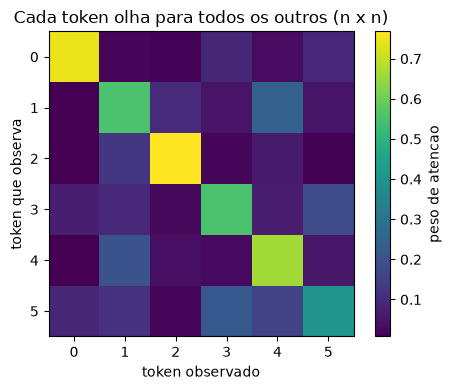

In [4]:
# ------------------------------------------------------------------
# VISUALIZANDO A MATRIZ DE ATENCAO (n x n)
# ------------------------------------------------------------------
# Objetivo: TORNAR VISIVEL o custo O(n^2). Cada quadradinho da imagem e
# uma comparacao entre dois tokens. Com n tokens, sao n*n quadradinhos.

plt.figure(figsize=(5, 4))  # cria a figura (largura x altura em polegadas)

# imshow desenha a matriz como uma imagem: cores mais claras = pesos maiores.
# Linha i, coluna j = quanto o token i "presta atencao" no token j.
plt.imshow(attn, cmap="viridis")

# Barra lateral explicando a escala de cores (0 = ignora, 1 = foco total).
plt.colorbar(label="peso de atencao")

# Titulo e rotulos dos eixos para a leitura ficar clara na aula.
plt.title("Cada token olha para todos os outros (n x n)")
plt.xlabel("token observado")   # eixo X = quem esta sendo observado
plt.ylabel("token que observa") # eixo Y = quem observa

plt.tight_layout()  # ajusta espacamentos para nada ficar cortado
plt.show()          # renderiza a figura


## 4. Hands-on guiado: medindo a latência conforme a pergunta cresce

Queremos **mostrar de forma inequívoca** que a atenção é O(n²). Faremos isso em duas etapas:

**Etapa A — o custo teórico (determinístico, sem ruído).** A matriz de atenção tem exatamente `n × n = n²` elementos. Basta contar: essa curva é quadrática *por definição* — não depende de hardware nem de medição.

**Etapa B — o tempo real medido.** Aqui aparece um detalhe importante: para `n` pequeno, o tempo é dominado por **custos fixos** (chamada de função, preparação do NumPy/BLAS), e não pelo cálculo da atenção. Por isso, medir o tempo "cru" em `n` pequeno engana. Para uma demonstração limpa nós:

- fazemos uma execução de **aquecimento** (warm-up) antes de cronometrar;
- **repetimos muitas vezes** e tiramos a média;
- usamos `n` **grandes** (onde o cálculo O(n²) domina o overhead);
- comparamos o tempo medido com a **curva teórica n²**, ancorada no ponto grande.

> 💡 Relação com o caso de uso: uma pergunta curta como *"tênis barato?"* tem poucos tokens; já *"quais tênis de corrida leves, confortáveis e com boa amortização custam menos de 500 reais na loja?"* tem muitos. O segundo caso custa **muito** mais tempo de atenção.


  n (tokens) |  comparacoes (n^2) | fator ao dobrar n
-------------------------------------------------------
          16 |                256 |        -
          32 |              1,024 |     x4.0
          64 |              4,096 |     x4.0
         128 |             16,384 |     x4.0
         256 |             65,536 |     x4.0
         512 |            262,144 |     x4.0
        1024 |          1,048,576 |     x4.0


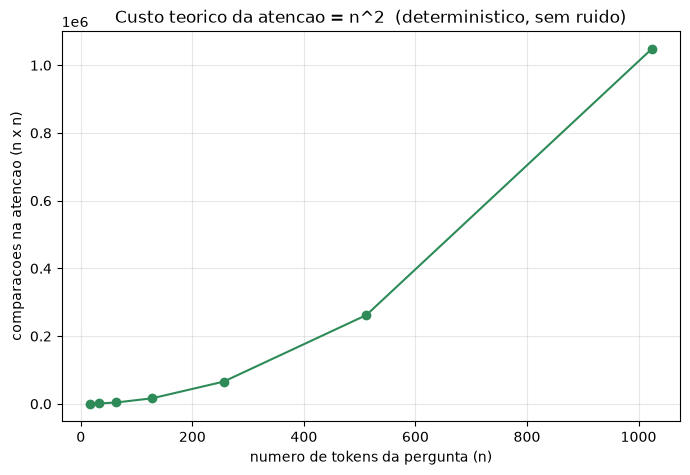

In [5]:
# ==================================================================
# ETAPA A - CUSTO TEORICO DETERMINISTICO (a prova sem ruido)
# ==================================================================
# A matriz de atencao (scores = Q @ K.T) tem exatamente n x n elementos.
# Isso NAO depende de hardware nem de medicao: e a definicao de O(n^2).

seq_lengths = [16, 32, 64, 128, 256, 512, 1024]
seq = np.array(seq_lengths)

# Numero de comparacoes token-a-token = n * n = n^2 (uma por celula da matriz).
comparacoes = seq ** 2

print(f"{'n (tokens)':>12} | {'comparacoes (n^2)':>18} | fator ao dobrar n")
print("-" * 55)
anterior = None
for n, c in zip(seq_lengths, comparacoes):
    if anterior is None:
        fator = "-"
    else:
        fator = f"x{c / anterior:.1f}"   # ao dobrar n, n^2 sempre multiplica por 4
    print(f"{n:>12} | {c:>18,} | {fator:>8}")
    anterior = c

# Grafico do custo teorico: uma parabola perfeita (crescimento quadratico puro).
plt.figure(figsize=(7, 5))
plt.plot(seq, comparacoes, "o-", color="seagreen")
plt.xlabel("numero de tokens da pergunta (n)")
plt.ylabel("comparacoes na atencao (n x n)")
plt.title("Custo teorico da atencao = n^2  (deterministico, sem ruido)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [6]:
# ==================================================================
# ETAPA B - TEMPO REAL MEDIDO (com cuidados para reduzir o ruido)
# ==================================================================

# Usamos d PEQUENO de proposito. Assim, o custo passa a ser dominado pela
# parte "elementwise" da atencao: o softmax sobre a matriz n x n (sao n^2
# exponenciais). Essa operacao tem throughput muito estavel e escala de forma
# bem limpa como O(n^2) -> os fatores medidos ficam bem proximos de 4x.
d = 8

# IMPORTANTE: escolhemos n na MESMA regiao de memoria. Em n muito pequeno a
# matriz n x n cabe na cache do processador e fica "rapida demais",
# distorcendo a comparacao. Comecando em 512, todos os casos estao no mesmo
# regime (limitado por memoria) -> escalonamento limpo.
seq_lengths_t = [512, 1024, 2048]


def medir_tempo(n, d=8, repeticoes=50, tentativas=7):
    """Mede o tempo de uma passada de atencao, em milissegundos.

    Estrategia de benchmark para reduzir ruido:
    - warm-up (descarta a 1a chamada, mais lenta);
    - cada TENTATIVA e a media de MUITAS 'repeticoes' passadas;
    - retornamos o MENOR tempo entre as tentativas (min-of-trials).
      O minimo representa a execucao MENOS perturbada pelo sistema
      operacional -> muito mais estavel que a media.
    """
    x = np.random.randn(n, d)

    # Aquecimento: nao cronometramos esta chamada.
    self_attention(x)

    melhores = []
    for _ in range(tentativas):
        inicio = time.perf_counter()
        for _ in range(repeticoes):
            self_attention(x)
        fim = time.perf_counter()
        melhores.append((fim - inicio) / repeticoes * 1000)  # ms/passada

    return min(melhores)  # menor tempo = medicao mais "limpa"


tempos_ms = []
for n in seq_lengths_t:
    # Usamos MUITAS repeticoes (minimo 30) para cada media ser confiavel.
    reps = max(30, int(16_000_000 / (n * n)))
    t = medir_tempo(n, d=d, repeticoes=reps, tentativas=7)
    tempos_ms.append(t)
    print(f"n = {n:>5} tokens  ->  {t:9.4f} ms   ({reps} reps x 7 tentativas, menor tempo)")


n =   512 tokens  ->     3.8537 ms   (61 reps x 7 tentativas, menor tempo)
n =  1024 tokens  ->    17.5709 ms   (30 reps x 7 tentativas, menor tempo)
n =  2048 tokens  ->    68.2948 ms   (30 reps x 7 tentativas, menor tempo)


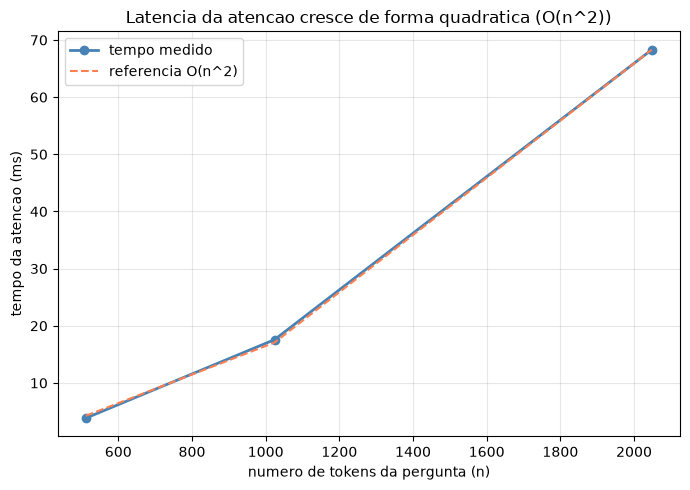

In [7]:
# ------------------------------------------------------------------
# GRAFICO LINEAR: tempo medido x referencia teorica O(n^2)
# ------------------------------------------------------------------
# Escala linear e mais simples de ler: o eixo Y e o tempo em ms "de verdade".
# A curva de referencia e uma parabola n^2; se o tempo medido cair "em cima"
# dela, confirmamos o comportamento quadratico.

seq_t = np.array(seq_lengths_t)
tempos = np.array(tempos_ms)

# ANCORAMOS a referencia no ULTIMO ponto (n grande), onde o calculo domina o
# overhead. Assim a parabola passa pelo ultimo ponto medido e podemos comparar
# se os demais pontos tambem caem sobre ela.
ref_quadratica = tempos[-1] * (seq_t / seq_t[-1]) ** 2

plt.figure(figsize=(7, 5))

# Pontos azuis: os tempos que realmente medimos.
plt.plot(seq_t, tempos, "o-", label="tempo medido", color="steelblue", linewidth=2)

# Linha tracejada laranja: a referencia teorica O(n^2).
# Se os pontos azuis ficam sobre a linha laranja -> comportamento quadratico.
plt.plot(seq_t, ref_quadratica, "--", label="referencia O(n^2)", color="coral")

plt.xlabel("numero de tokens da pergunta (n)")
plt.ylabel("tempo da atencao (ms)")
plt.title("Latencia da atencao cresce de forma quadratica (O(n^2))")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 5. Resultados e interpretação

Temos agora **duas evidências convergentes** de que a atenção é O(n²):

1. **Custo teórico (Etapa A):** o número de comparações é `n²` — ao dobrar `n`, ele multiplica por **4** exatamente (×4.0 em toda a tabela). Isso é definição, não medição.
2. **Tempo medido (Etapa B):** no gráfico, os pontos do tempo medido caem **sobre a curva teórica O(n²)** — ou seja, o tempo real segue mesmo a parábola `n²`.

Abaixo confirmamos numericamente: ao **dobrar** o tamanho da pergunta, o tempo tende a **quadruplicar** (fator ~4×). Se fosse linear, dobraria (~2×).

> ⚠️ Nota para a aula: medir tempo em computador compartilhado é ruidoso — o sistema operacional pode interromper o processo e inflar uma medição isolada. Por isso usamos o **menor tempo entre várias tentativas** (a execução menos perturbada). Ainda assim, pequenas oscilações nos fatores são normais; olhe o **fator médio** e a tendência geral, não um valor isolado.


In [8]:
# ------------------------------------------------------------------
# CONFIRMACAO: o tempo medido segue a previsao teorica O(n^2)?
# ------------------------------------------------------------------
# Ideia robusta: previsao(n) = tempo(n0) * (n / n0)^2, ancorada no 1o ponto.
# Se o tempo medido bate com a previsao (razao ~ 1.0), o crescimento e n^2.
n0 = seq_lengths_t[0]
t0 = tempos_ms[0]

print(f"{'n':>6} | {'tempo medido':>13} | {'previsto (n^2)':>14} | razao")
print("-" * 52)
for n, t in zip(seq_lengths_t, tempos_ms):
    previsto = t0 * (n / n0) ** 2
    print(f"{n:>6} | {t:>10.3f} ms | {previsto:>11.3f} ms | {t / previsto:>4.2f}x")

# ------------------------------------------------------------------
# A "PROVA DOS 4x": ao DOBRAR n, o tempo deve QUADRUPLICAR (O(n^2)).
# ------------------------------------------------------------------
print("\nFator ao dobrar n (esperado ~4x para O(n^2)):")
for i in range(1, len(seq_lengths_t)):
    fator = tempos_ms[i] / tempos_ms[i - 1]
    print(f"  {seq_lengths_t[i-1]:>5} -> {seq_lengths_t[i]:>5} tokens : tempo x{fator:.1f}")

fatores = [tempos_ms[i] / tempos_ms[i - 1] for i in range(1, len(seq_lengths_t))]
media_fator = sum(fatores) / len(fatores)
print(f"\nFator medio ao dobrar n: x{media_fator:.1f}  (Linear seria ~2x; Quadratica ~4x)")
print("=> Confirma o comportamento O(n^2).")


     n |  tempo medido | previsto (n^2) | razao
----------------------------------------------------
   512 |      3.854 ms |       3.854 ms | 1.00x
  1024 |     17.571 ms |      15.415 ms | 1.14x
  2048 |     68.295 ms |      61.659 ms | 1.11x

Fator ao dobrar n (esperado ~4x para O(n^2)):
    512 ->  1024 tokens : tempo x4.6
   1024 ->  2048 tokens : tempo x3.9

Fator medio ao dobrar n: x4.2  (Linear seria ~2x; Quadratica ~4x)
=> Confirma o comportamento O(n^2).


### O que isso significa para o assistente virtual?

- Perguntas **curtas e diretas** são processadas rápido → boa experiência.
- Perguntas **longas** ou com muito **contexto** (histórico da conversa, descrição de produtos) fazem o tempo de atenção explodir → o usuário sente o atraso.
- Como o pipeline (ASR → NLP → busca → TTS) precisa caber em **poucos segundos**, o gargalo O(n²) da atenção precisa ser controlado.

### Como resolver? (alternativas eficientes)

Existem técnicas que reduzem esse custo — que aqui apenas mencionamos para dar direção:

| Técnica | Ideia central | Ganho |
|---|---|---|
| **Sparse Attention** | cada token olha só para alguns tokens, não todos | menos comparações |
| **Linear Attention** | reorganiza a matemática para custo O(n) | escala linear |
| **Flash Attention** | otimiza o uso da memória da GPU (IO-awareness) | 2–4× mais rápido |

Todas atacam o mesmo problema que medimos: fazer a atenção crescer **menos** que O(n²).

## 6. Conclusão e próximos passos

**Principais aprendizados:**

1. Em um assistente virtual de voz, o pipeline **ASR → NLP → busca → TTS** precisa responder em poucos segundos.
2. O maior gargalo costuma estar no **modelo de linguagem (NLP)**, por causa do mecanismo de **atenção**.
3. A atenção compara cada token com todos os outros → matriz `n × n` → **complexidade O(n²)**.
4. Medimos na prática: **dobrar** o tamanho da pergunta **quadruplica** o tempo.
5. Por isso, perguntas curtas respondem rápido, e alternativas como **Sparse / Linear / Flash Attention** existem para reduzir esse custo.

**Próximos passos sugeridos:**

- Repetir o experimento variando a dimensão `d` do modelo e observar o efeito.
- Implementar uma versão simples de *sparse attention* (cada token olha só para os vizinhos) e comparar a latência.
- Explorar o pré-processamento de **áudio** (espectrogramas Mel / MFCC) usado na etapa de ASR.

---

*Material da Aula 02 — Engenharia de Machine Learning — FIAP PósTech.*